# Analyse des doublons

**Projet :** BrainScanAI - détection semi-supervisée de tumeurs cérébrales  
**Étape :** 2 - Préparer le jeu de données  
**Auteur :** Kilian Lefevre

---

## Objectif du notebook

Le notebook `01.0` a repéré des fichiers binaires identiques. Ce notebook caractérise ces doublons et définit la règle de déduplication qui sera ensuite implémentée dans `brain_mri.dataset`. Il répond aux questions suivantes :

- Où se situent les doublons : parmi les images non annotées, annotées, ou entre les deux ?
- Existe-t-il des labels contradictoires au sein d'un groupe de doublons ?
- Quelle copie conserver, et que devient le sous-ensemble annoté ?
- Existe-t-il des quasi-doublons que le hash binaire ne détecte pas ?

Les données restent **immutables** dans `data/raw/` : ce notebook ne supprime aucun fichier et ne fait que décider de la règle à appliquer.

## 1. Chargement

L'inventaire et les empreintes SHA-256 proviennent de `brain_mri.dataset`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.neighbors import NearestNeighbors

from brain_mri.config import RAW_DATA_DIR
from brain_mri.dataset import add_file_hash, build_inventory

pd.set_option("display.max_colwidth", 100)
plt.style.use("seaborn-v0_8-whitegrid")

images = add_file_hash(build_inventory(RAW_DATA_DIR))
print(f"{len(images):,} images, dont {images['is_labeled'].sum():,} annotées.")

2026-10-16 11:36:14.273 | INFO     | brain_mri.config:<module>:11 - PROJ_ROOT path is: /Users/kilian/Documents/Repositories/OpenClassrooms/OC-Appliquez-des-approches-semi-supervisees


1,506 images, dont 100 annotées.


## 2. Doublons exacts

Un groupe rassemble tous les fichiers de même empreinte SHA-256. Pour chaque groupe, on compte les copies par origine (`cancer`, `normal`, `sans_label`).

In [2]:
duplicated = images.loc[images.duplicated("sha256", keep=False)]

groups = duplicated.groupby("sha256").agg(
    taille=("image_id", "size"),
    n_cancer=("label", lambda labels: (labels == "cancer").sum()),
    n_normal=("label", lambda labels: (labels == "normal").sum()),
    n_sans_label=("is_labeled", lambda flags: (~flags).sum()),
)

composition = (
    groups.groupby(["taille", "n_cancer", "n_normal", "n_sans_label"])
    .size()
    .rename("nombre_groupes")
    .reset_index()
)
display(composition)

n_excess = len(duplicated) - len(groups)
print(
    f"{len(groups)} groupes, {len(duplicated)} fichiers impliqués, {n_excess} copies en trop."
)

,taille,n_cancer,n_normal,n_sans_label,nombre_groupes
0,2,0,0,2,55
1,2,0,1,1,21
2,2,1,0,1,8
3,3,0,0,3,4
4,3,0,1,2,1
5,3,0,2,1,1


90 groupes, 186 fichiers impliqués, 96 copies en trop.


### Cohérence des labels

Un même contenu ne doit jamais porter deux labels différents (`cancer` et `normal`). Dans le cas contraire, il faudrait le retirer du jeu annoté.

In [3]:
labels_per_group = duplicated.groupby("sha256")["label"].nunique()
assert (labels_per_group <= 1).all(), (
    "Des groupes ont des labels contradictoires."
)

groups_with_label = groups[(groups["n_cancer"] + groups["n_normal"]) > 0]
print("Aucun groupe n'a de labels contradictoires.")
print(
    f"Groupes contenant au moins une image annotée : {len(groups_with_label)}"
)

Aucun groupe n'a de labels contradictoires.
Groupes contenant au moins une image annotée : 31


### Doublons au sein du jeu annoté

Une même image annotée en double réduit mécaniquement la taille du jeu d'évaluation.

In [4]:
labeled = images.loc[images["is_labeled"]]
labeled_duplicates = labeled.loc[
    labeled.duplicated("sha256", keep=False),
    ["image_id", "subset", "label", "sha256"],
].sort_values("sha256")
display(labeled_duplicates)

,image_id,subset,label,sha256
77,71f8bd3d-58a9-485f-860d-cfca5fd01bae,normal,normal,cc5f6b195070910cdf3298a78866b81334dc96262ff4ba1922229f508d682cc2
96,d86f39ec-55a1-4484-bcfd-78d5debb43f8,normal,normal,cc5f6b195070910cdf3298a78866b81334dc96262ff4ba1922229f508d682cc2


## 3. Règle de déduplication

Pour chaque groupe, on conserve **une seule copie**, choisie ainsi :

1. une copie **annotée** si le groupe en contient une, afin de ne jamais perdre l'information du label ;
2. sinon, la copie dont l'`image_id` est le plus petit, pour un choix reproductible.

Les copies non annotées d'une image annotée sont donc supprimées : elles créeraient une fuite si elles étaient pseudo-labellisées ou placées dans un autre fold.

In [5]:
deduplicated = (
    images.sort_values(
        ["sha256", "is_labeled", "image_id"], ascending=[True, False, True]
    )
    .drop_duplicates("sha256", keep="first")
    .sort_values(["subset", "image_id"])
    .reset_index(drop=True)
)

assert deduplicated["sha256"].is_unique
assert set(deduplicated["sha256"]) == set(images["sha256"]), (
    "Un contenu a disparu."
)
assert deduplicated.loc[deduplicated["is_labeled"], "sha256"].nunique() == (
    images.loc[images["is_labeled"], "sha256"].nunique()
), "Une image annotée a été perdue."

summary = pd.concat(
    {
        "avant": images.groupby("subset").size(),
        "après": deduplicated.groupby("subset").size(),
    },
    axis=1,
)
summary["supprimées"] = summary["avant"] - summary["après"]
summary.loc["total"] = summary.sum()
display(summary)

,avant,après,supprimées
subset,,,
cancer,50,50,0
normal,50,49,1
sans_label,1406,1311,95
total,1506,1410,96


## 4. Quasi-doublons

Le hash binaire ne détecte pas une image ré-encodée ou légèrement modifiée. Pour estimer ce risque, chaque image dédupliquée est réduite à une miniature **32 × 32 en niveaux de gris**, puis on cherche son plus proche voisin (distance euclidienne, pixels dans [0, 1]).

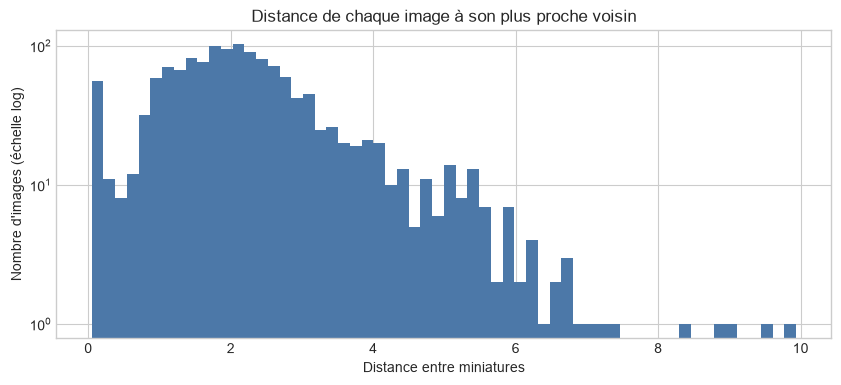

In [6]:
THUMBNAIL_SIZE = 32


def load_thumbnail(filepath) -> np.ndarray:
    """Retourne une miniature en niveaux de gris, aplatie, valeurs dans [0, 1]."""
    with Image.open(filepath) as image:
        thumbnail = image.convert("L").resize(
            (THUMBNAIL_SIZE, THUMBNAIL_SIZE), Image.Resampling.BILINEAR
        )
    return np.asarray(thumbnail, dtype=np.float32).ravel() / 255


thumbnails = np.stack(
    [load_thumbnail(path) for path in deduplicated["filepath"]]
)

distances, neighbors = (
    NearestNeighbors(n_neighbors=2).fit(thumbnails).kneighbors(thumbnails)
)
nearest_distance = distances[:, 1]
nearest_index = neighbors[:, 1]

figure, axis = plt.subplots(figsize=(10, 4))
axis.hist(nearest_distance, bins=60, color="#4C78A8")
axis.set_yscale("log")
axis.set(
    title="Distance de chaque image à son plus proche voisin",
    xlabel="Distance entre miniatures",
    ylabel="Nombre d'images (échelle log)",
)
plt.show()

La distribution présente une queue de valeurs très faibles, nettement séparée du reste. On retient un seuil de **0,15** et on inspecte visuellement les paires correspondantes.

In [7]:
NEAR_DUPLICATE_THRESHOLD = 0.15

pairs = (
    pd.DataFrame(
        {
            "a": np.arange(len(deduplicated)),
            "b": nearest_index,
            "distance": nearest_distance,
        }
    )
    .query("distance < @NEAR_DUPLICATE_THRESHOLD")
    .assign(
        a_b=lambda frame: frame[["a", "b"]].apply(
            lambda row: tuple(sorted(row)), axis=1
        )
    )
    .drop_duplicates("a_b")
    .drop(columns="a_b")
)
for side in ("a", "b"):
    pairs[f"subset_{side}"] = deduplicated["subset"].to_numpy()[pairs[side]]
pairs["implique_annotee"] = pairs["subset_a"].ne("sans_label") | pairs[
    "subset_b"
].ne("sans_label")
pairs = pairs.sort_values(
    ["implique_annotee", "distance"], ascending=[False, True]
).reset_index(drop=True)

print(
    f"{len(pairs)} paires de quasi-doublons (distance < {NEAR_DUPLICATE_THRESHOLD})."
)
display(
    pairs.groupby(["subset_a", "subset_b"])
    .size()
    .rename("paires")
    .reset_index()
)

24 paires de quasi-doublons (distance < 0.15).


,subset_a,subset_b,paires
0,normal,normal,1
1,normal,sans_label,5
2,sans_label,sans_label,18


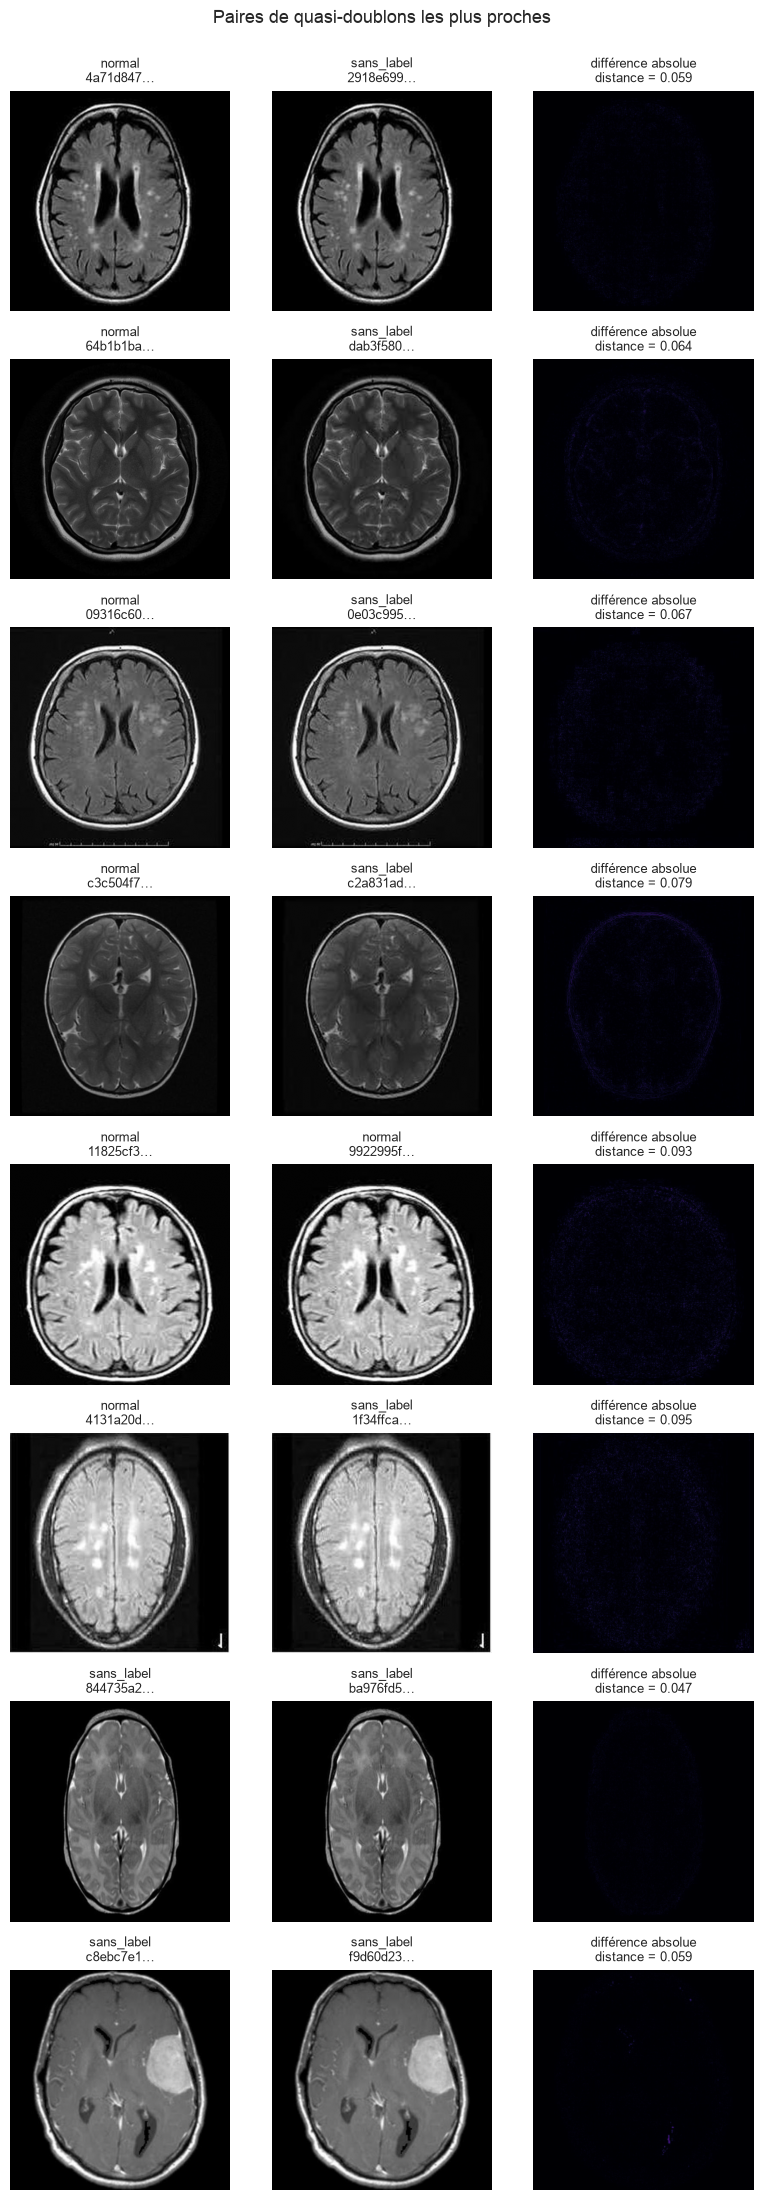

In [ ]:
n_pairs_to_show = 8
shown = pairs.head(n_pairs_to_show)

figure, axes = plt.subplots(
    len(shown), 3, figsize=(8, 2.8 * len(shown)), squeeze=False
)
for axis_row, (_, pair) in zip(axes, shown.iterrows(), strict=True):
    arrays = []
    for axis, side in zip(axis_row[:2], ("a", "b"), strict=True):
        row = deduplicated.iloc[int(pair[side])]
        with Image.open(row["filepath"]) as image:
            array = np.asarray(image.convert("L"), dtype=np.float32)
        arrays.append(array)
        axis.imshow(array, cmap="gray", vmin=0, vmax=255)
        axis.set_title(f"{row['subset']}\n{row['image_id'][:8]}…", fontsize=9)

    axis_row[2].imshow(
        np.abs(arrays[0] - arrays[1]), cmap="magma", vmin=0, vmax=255
    )
    axis_row[2].set_title(
        f"différence absolue\ndistance = {pair['distance']:.3f}", fontsize=9
    )
    for axis in axis_row:
        axis.axis("off")

figure.suptitle("Paires de quasi-doublons les plus proches", fontsize=13)
plt.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()

### Effet de la déduplication des quasi-doublons

Les paires inspectées sont visuellement identiques : la différence absolue est quasi nulle. On leur applique la même règle qu'aux doublons exacts : une copie annotée est conservée en priorité, puis l'`image_id` le plus petit.

In [9]:
def hash_to_remove(pair: pd.Series) -> str:
    """Retourne le hash de la copie à supprimer dans une paire de quasi-doublons."""
    candidates = [
        deduplicated.iloc[int(pair["a"])],
        deduplicated.iloc[int(pair["b"])],
    ]
    candidates.sort(key=lambda row: (not row["is_labeled"], row["image_id"]))
    return candidates[1]["sha256"]


removed_hashes = {hash_to_remove(pair) for _, pair in pairs.iterrows()}
near_deduplicated = deduplicated.loc[
    ~deduplicated["sha256"].isin(removed_hashes)
]

summary_near = pd.concat(
    {
        "brut": images.groupby("subset").size(),
        "sans doublons exacts": deduplicated.groupby("subset").size(),
        "sans quasi-doublons": near_deduplicated.groupby("subset").size(),
    },
    axis=1,
)
summary_near.loc["total"] = summary_near.sum()
display(summary_near)

,brut,sans doublons exacts,sans quasi-doublons
subset,,,
cancer,50,50,50
normal,50,49,48
sans_label,1406,1311,1289
total,1506,1410,1387


## Conclusion de l'analyse

### Synthèse

- **90 groupes de doublons exacts** (186 fichiers) : 96 copies sont en trop. Aucun groupe n'a de labels contradictoires.
- **31 groupes contiennent une image annotée**, dont 29 avec une copie non annotée : sans déduplication, ces copies pourraient fuiter entre apprentissage et évaluation.
- Une image `normal` est annotée **deux fois** : le jeu annoté passe de 50 à 49 images `normal` après déduplication exacte.
- **24 paires de quasi-doublons** (distance < 0,15) ont été trouvées en plus. Visuellement, les images sont identiques. 6 paires impliquent une image annotée.

### Décision

Règle de déduplication : conserver **une copie par groupe**, en priorité une copie annotée, sinon l'`image_id` le plus petit.

| Jeu | Brut | Sans doublons exacts | Sans quasi-doublons |
|---|---|---|---|
| `cancer` | 50 | 50 | 50 |
| `normal` | 50 | 49 | 48 |
| `sans_label` | 1 406 | 1 311 | 1 289 |
| **Total** | 1 506 | 1 410 | 1 387 |

La déduplication exacte est à implémenter dans `brain_mri.dataset`. Les quasi-doublons relèvent d'un seuil choisi par inspection : on les traite avec la même règle, mais ce seuil devra rester une constante documentée. Le jeu annoté final compterait **98 images** (50 `cancer`, 48 `normal`) ; il reste équilibré à deux images près, ce qui est à garder en tête pour les métriques.

L'étape suivante est de factoriser cette règle dans `dataset.py` et d'écrire le manifeste dédupliqué dans `data/interim/`.
